# 08 — Shapelet score vs relative wind direction

**Exploratory detour, not (yet) referenced in `main.tex`.**

Hypothesis: part of the bad image quality comes from tube / dome seeing, and pointing
the telescope *into* the wind flushes the tube and helps. If so, image quality should be
best at small relative wind angle and degrade as the wind moves round to the back of the
telescope.

Produces
* `fig/score_vs_wind_direction.pdf` — visit-median shapelet score vs relative wind direction, DP2 and post-DP2.
* `fig/score_vs_wind_direction_by_speed.pdf` — score (top) and measured PSF FWHM (bottom) vs relative wind direction in four wind-speed brackets, with a straight-line trend for each.

**Definitions**
* Relative wind direction $\Delta\phi = |\,\mathrm{wrap}_{\pm180}(\phi_{\rm tel} - \phi_{\rm wind})\,| \in [0^\circ, 180^\circ]$.
  $\Delta\phi = 0^\circ$: telescope points into the wind. $\Delta\phi = 180^\circ$: wind blows from behind.
* $\phi_{\rm tel}$ = consDB `cdb_lsstcam.exposure.azimuth` (focal-plane centre at mid-exposure; N = 0°, E = 90°).
* $\phi_{\rm wind}$ = consDB `cdb_lsstcam.exposure.wind_dir`. The schema says only *"Wind direction."*
  We **assume the meteorological convention** (direction the wind comes *from*, N = 0°, E = 90°).
  The median is ≈22°, consistent with the predominantly northerly wind on Cerro Pachón.
  If the column were the "blowing towards" convention, the x-axis below flips ($\Delta\phi \to 180^\circ - \Delta\phi$).
* Cut: telescope altitude $< 70^\circ$ (near zenith the azimuth says little about how the tube faces the wind).
* Score: paper definition (odd-$m$, `plot_config.shapelet_score`), median over rafts per (visit, band), as in `06`.

In [1]:
import importlib.util, os
spec = importlib.util.spec_from_file_location('plot_config', 'plot_config.py')
plot_config = importlib.util.module_from_spec(spec); spec.loader.exec_module(plot_config)
from plot_config import (BANDS, PALETTE, TIER_EDGES, TIER_COLORS, FIG, DATA, FWHM_PER_SIGMA,
                         MultipleLocator, LogLocator, apply_style, bvec_path,
                         shapelet_score, day_obs)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr
import requests

apply_style()
EPOCHS = {'DP2': 'dp2all', 'Post-DP2': 'postdp2'}
EPOCH_COLORS = {'DP2': PALETTE[2], 'Post-DP2': PALETTE[0]}

ALT_MAX = 70.0                                   # deg; keep visits with altitude < ALT_MAX
CONSDB_URL = 'http://consdb-pq.consdb:8080/consdb'
CACHE = DATA / 'consdb_exposure_wind.pq'         # consDB snapshot, so the notebook runs without consDB

## Wind and pointing from consDB

One query on `cdb_lsstcam.exposure` covers every science exposure of both epochs (≈2 s).
The result is cached to `../../data/consdb_exposure_wind.pq`; set `REFRESH = True` to re-query.
consDB resolves from the RSP and (as of 2026-11-07) from the SDF interactive nodes.

In [2]:
def fetch_exposure_conditions(day_start=20250401, day_end=20260731):
    # Pointing and weather for every science exposure, from consDB cdb_lsstcam.exposure.
    os.environ['no_proxy'] = os.environ.get('no_proxy', '') + ',.consdb'
    query = f'''
        SELECT exposure_id AS visit_id, altitude, azimuth,
               wind_dir, wind_speed, air_temp, dimm_seeing
        FROM cdb_lsstcam.exposure
        WHERE img_type = 'science' AND day_obs BETWEEN {day_start} AND {day_end}
    '''
    r = requests.post(f'{CONSDB_URL}/query', json={'query': query}, timeout=300)
    r.raise_for_status()
    j = r.json()
    df = pd.DataFrame(j['data'], columns=j['columns'])
    df['visit_id'] = df['visit_id'].astype(np.int64)
    for c in df.columns[1:]:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df

REFRESH = False
if CACHE.exists() and not REFRESH:
    cond = pd.read_parquet(CACHE)
    print(f'read {len(cond):,} science exposures from {CACHE}')
else:
    cond = fetch_exposure_conditions()
    cond.to_parquet(CACHE, index=False)
    print(f'fetched {len(cond):,} science exposures from consDB -> {CACHE}')

print(cond[['altitude', 'azimuth', 'wind_dir', 'wind_speed']].describe().round(2).T)

read 99,385 science exposures from /sdf/data/rubin/user/ztq1996/psf-rubin/psf_zernike/data/consdb_exposure_wind.pq
              count    mean     std    min     25%     50%     75%     max
altitude    99385.0   58.53   11.77  17.11   50.68   60.13   68.84   85.15
azimuth     99385.0  212.73  105.26   0.01  140.17  228.17  300.91  360.00
wind_dir    99385.0   60.58   89.54   0.00   14.48   21.79   37.85  360.00
wind_speed  99385.0    5.27    3.30   0.00    2.75    4.75    7.42   20.60


## Per-visit score, FWHM and relative wind angle

`fwhm` is the measured PSF FWHM, $2.3548\,\sigma$ with $\sigma$ the HSM adaptive-moment size
stored in the shapelet library, median over rafts.

In [3]:
def visit_table(tag):
    # Median over rafts of the shapelet score and PSF FWHM, per (visit_id, band).
    out = []
    for band in BANDS:
        d = np.load(bvec_path(band, tag))
        out.append(pd.DataFrame(dict(visit_id=d['visit'].astype(np.int64), band=band,
                                     score=shapelet_score(d['bvec']),
                                     fwhm=d['sigma'] * FWHM_PER_SIGMA)))
    df = pd.concat(out, ignore_index=True)
    return df.groupby(['visit_id', 'band'], as_index=False)[['score', 'fwhm']].median()


def relative_wind_angle(azimuth, wind_dir):
    # |azimuth - wind_dir| folded into [0, 180] deg; 0 = pointing into the wind.
    return np.abs((np.asarray(azimuth) - np.asarray(wind_dir) + 180.0) % 360.0 - 180.0)

assert np.allclose(relative_wind_angle([0, 10, 350, 180, 90, 300],
                                       [0, 350, 10, 0, 270, 30]),
                   [0, 20, 20, 180, 180, 90])

data = {}
for epoch, tag in EPOCHS.items():
    v = visit_table(tag)
    m = v.merge(cond, on='visit_id', how='inner')
    m['dphi'] = relative_wind_angle(m['azimuth'], m['wind_dir'])
    m['night'] = day_obs(m['visit_id'])
    sel = m[m['altitude'] < ALT_MAX].reset_index(drop=True)
    data[epoch] = sel
    print(f'{epoch:>9}: {len(v):,} (visit, band) scored  ->  {len(m):,} matched in consDB  ->  '
          f'{len(sel):,} with altitude < {ALT_MAX:.0f} deg, {sel.night.nunique()} nights')

      DP2: 29,502 (visit, band) scored  ->  29,502 matched in consDB  ->  25,266 with altitude < 70 deg, 127 nights


 Post-DP2: 64,920 (visit, band) scored  ->  64,920 matched in consDB  ->  49,983 with altitude < 70 deg, 115 nights


## Binned statistics with a night-block bootstrap

Visits in one night share the wind and often the same part of the sky, so they are not
independent. Error bars come from resampling **whole nights** with replacement; resampling
single visits would make them several times too small.

In [4]:
EDGES = np.arange(0, 181, 15)
MID = 0.5 * (EDGES[:-1] + EDGES[1:])
N_BOOT = 300
MIN_PER_BIN = 30
INTO, BEHIND = 45.0, 135.0     # 'into the wind' dphi < 45 deg, 'wind from behind' dphi > 135 deg

def binned_stat(x, y, stat=np.median, edges=EDGES):
    k = np.digitize(x, edges[1:-1])
    out = np.full(len(edges) - 1, np.nan)
    for i in range(len(out)):
        yi = y[k == i]
        if len(yi) >= MIN_PER_BIN:
            out[i] = stat(yi)
    return out


def night_bootstrap(df, fn, n_boot=N_BOOT, seed=42):
    # fn(sub_df_arrays) -> 1-d array. Returns estimate and 16/84th percentiles over night resamples.
    df = df.reset_index(drop=True)
    arrs = {c: df[c].to_numpy() for c in ('dphi', 'score', 'fwhm', 'band')}
    est = fn(arrs)
    nights = list(df.groupby('night').indices.values())
    rng = np.random.default_rng(seed)
    boots = np.empty((n_boot, np.size(est)))
    for b in range(n_boot):
        ii = np.concatenate([nights[p] for p in rng.integers(0, len(nights), len(nights))])
        boots[b] = fn({c: a[ii] for c, a in arrs.items()})
    lo, hi = np.nanpercentile(boots, [16, 84], axis=0)
    return est, lo, hi


def binned(ycol, stat=np.median):
    return lambda a: binned_stat(a['dphi'], a[ycol], stat=stat)


def into_vs_behind(ycol, stat=np.median):
    # [stat(into), stat(behind), behind/into]
    def fn(a):
        s_in = stat(a[ycol][a['dphi'] < INTO])
        s_bh = stat(a[ycol][a['dphi'] > BEHIND])
        return np.array([s_in, s_bh, s_bh / s_in])
    return fn

frac_high = lambda y: np.mean(y >= TIER_EDGES[1])      # fraction in HIGH or VERY HIGH tier

for epoch, df in data.items():
    n, _ = np.histogram(df['dphi'], EDGES)
    print(f'{epoch:>9} visits per {EDGES[1]:.0f}-deg bin:', n.tolist())

      DP2 visits per 15-deg bin: [1682, 1864, 2376, 2620, 2867, 2649, 2694, 2053, 1860, 1842, 1452, 1307]
 Post-DP2 visits per 15-deg bin: [4159, 4079, 3822, 3829, 3588, 3600, 3946, 4084, 3823, 4634, 5386, 5033]


## Figure: shapelet score vs relative wind direction

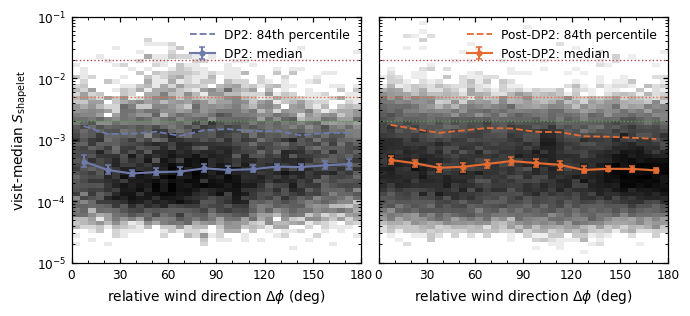

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.9), sharey=True,
                         gridspec_kw=dict(wspace=0.06))

allscore = np.concatenate([d['score'].to_numpy() for d in data.values()])
YLO, YHI = np.percentile(allscore[allscore > 0], [0.5, 99.8])
YLO, YHI = 10 ** np.floor(np.log10(YLO)), 10 ** np.ceil(np.log10(YHI))
ybins = np.logspace(np.log10(YLO), np.log10(YHI), 60)

fig1_stats = {}
for ax, (epoch, df) in zip(axes, data.items()):
    df = df[df['score'] > 0]
    ax.hist2d(df['dphi'], df['score'], bins=(np.arange(0, 181, 5), ybins),
              norm=LogNorm(), cmap='Greys', rasterized=True)
    est, lo, hi = night_bootstrap(df, binned('score'))
    p84 = binned_stat(df['dphi'].to_numpy(), df['score'].to_numpy(),
                      stat=lambda v: np.percentile(v, 84))
    fig1_stats[epoch] = (est, lo, hi, p84)
    c = EPOCH_COLORS[epoch]
    ax.errorbar(MID, est, yerr=[est - lo, hi - est], fmt='o-', color=c, ms=3, lw=1.4,
                capsize=2, label=f'{epoch}: median')
    ax.plot(MID, p84, ls='--', color=c, lw=1.2, label=f'{epoch}: 84th percentile')
    for e, name in zip(TIER_EDGES, ['MEDIUM', 'HIGH', 'VERY HIGH']):
        ax.axhline(e, color=TIER_COLORS[name], ls=':', lw=0.9)
    ax.set_yscale('log')
    ax.set_xlim(0, 180); ax.set_ylim(YLO, YHI)
    ax.set_xlabel(r'relative wind direction $\Delta\phi$ (deg)')
    ax.xaxis.set_major_locator(MultipleLocator(30))
    ax.xaxis.set_minor_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10)))
    ax.legend(loc='upper right', frameon=False)

axes[0].set_ylabel(r'visit-median $S_{\rm shapelet}$')
fig.savefig(FIG / 'score_vs_wind_direction.pdf')
plt.show()

In [6]:
print(f'Visit-median score per {EDGES[1]:.0f}-deg bin (16-84% night bootstrap):')
for epoch, (est, lo, hi, p84) in fig1_stats.items():
    print(f'\n{epoch}')
    for m_, e_, l_, h_, p_ in zip(MID, est, lo, hi, p84):
        print(f'  dphi = {m_:5.1f}  median = {e_:.5f}  [{l_:.5f}, {h_:.5f}]   P84 = {p_:.5f}')

print('\nSpearman rank correlation with dphi (altitude < 70 deg):')
for epoch, df in data.items():
    r_s = spearmanr(df['dphi'], df['score']).statistic
    r_f = spearmanr(df['dphi'], df['fwhm']).statistic
    print(f'  {epoch:>9}: score rho = {r_s:+.3f}   FWHM rho = {r_f:+.3f}   N = {len(df):,}')

Visit-median score per 15-deg bin (16-84% night bootstrap):

DP2
  dphi =   7.5  median = 0.00044  [0.00036, 0.00057]   P84 = 0.00168
  dphi =  22.5  median = 0.00032  [0.00028, 0.00038]   P84 = 0.00124
  dphi =  37.5  median = 0.00028  [0.00025, 0.00032]   P84 = 0.00125
  dphi =  52.5  median = 0.00030  [0.00026, 0.00035]   P84 = 0.00135
  dphi =  67.5  median = 0.00030  [0.00026, 0.00036]   P84 = 0.00116
  dphi =  82.5  median = 0.00034  [0.00030, 0.00040]   P84 = 0.00143
  dphi =  97.5  median = 0.00032  [0.00029, 0.00038]   P84 = 0.00149
  dphi = 112.5  median = 0.00033  [0.00030, 0.00038]   P84 = 0.00138
  dphi = 127.5  median = 0.00036  [0.00033, 0.00041]   P84 = 0.00140
  dphi = 142.5  median = 0.00036  [0.00032, 0.00040]   P84 = 0.00118
  dphi = 157.5  median = 0.00038  [0.00033, 0.00044]   P84 = 0.00129
  dphi = 172.5  median = 0.00040  [0.00033, 0.00049]   P84 = 0.00129

Post-DP2
  dphi =   7.5  median = 0.00047  [0.00040, 0.00055]   P84 = 0.00174
  dphi =  22.5  median = 0.0

## Into the wind vs wind from behind

Compare visits with $\Delta\phi < 45^\circ$ against $\Delta\phi > 135^\circ$. If tube seeing is
flushed by the wind, the "behind / into" ratio should be **> 1** for every image-quality metric.

In [7]:
METRICS = [('median score',          'score', np.median),
           ('frac. score >= 0.005',  'score', frac_high),
           ('median FWHM (arcsec)',  'fwhm',  np.median)]

rows = []
for epoch, df in data.items():
    for label, col, stat in METRICS:
        est, lo, hi = night_bootstrap(df, into_vs_behind(col, stat))
        rows.append(dict(epoch=epoch, metric=label,
                         into=est[0], behind=est[1],
                         ratio=est[2], ratio_lo=lo[2], ratio_hi=hi[2],
                         n_into=(df['dphi'] < INTO).sum(), n_behind=(df['dphi'] > BEHIND).sum()))
contrast = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.5g}'.format):
    print(contrast.to_string(index=False))

   epoch               metric       into     behind   ratio  ratio_lo  ratio_hi  n_into  n_behind
     DP2         median score 0.00032948 0.00037861  1.1491    0.9488    1.3708    5922      4601
     DP2 frac. score >= 0.005   0.026511   0.019561 0.73783   0.53857    0.9514    5922      4601
     DP2 median FWHM (arcsec)     1.1205     1.1532  1.0292   0.99693    1.0734    5922      4601
Post-DP2         median score 0.00040981 0.00032912 0.80311   0.72285     0.912   12060     15053
Post-DP2 frac. score >= 0.005   0.024129   0.010828 0.44876   0.32588   0.59563   12060     15053
Post-DP2 median FWHM (arcsec)    0.95401     1.0603  1.1114    1.0848    1.1397   12060     15053


## Wind-speed brackets: does stronger wind help more?

* **Wind speed.** Wind direction is meaningless in a calm, and flushing should matter most
  when the wind is strong. If the hypothesis holds, the into-wind advantage should **grow
  with wind speed**. (`wind_speed == 0` occurs for a few thousand exposures and lands in the
  lowest bracket.)
* **PSF FWHM.** Tube seeing is turbulence; it mostly *broadens* the PSF symmetrically. The
  shapelet score is a *fraction* of total power, so extra symmetric blur lowers it at fixed
  optical asymmetry (the dilution effect noted in `06`). FWHM is therefore the more direct
  test of the tube-seeing hypothesis, and a falling score with a rising FWHM is not a contradiction.

For each bracket the markers are binned medians and the solid line is a straight-line fit
to them. We quote the fitted fractional change from $\Delta\phi = 0^\circ$ to $180^\circ$,
$\delta = y_{\rm fit}(180^\circ) / y_{\rm fit}(0^\circ) - 1$, with a night-block bootstrap
interval: $\delta > 0$ means image quality is worse with the wind from behind.

In [8]:
WS_CLASSES = [(0, 3,      r'$v_{\rm wind} < 3$ m/s',        PALETTE[2]),
              (3, 6,      r'$3 \leq v_{\rm wind} < 6$ m/s', PALETTE[1]),
              (6, 9,      r'$6 \leq v_{\rm wind} < 9$ m/s', PALETTE[0]),
              (9, np.inf, r'$v_{\rm wind} \geq 9$ m/s',     PALETTE[3])]


def trend(ycol):
    # Straight-line fit to the binned medians: [slope, intercept, fractional change 0 -> 180 deg].
    def fn(a):
        y = binned_stat(a['dphi'], a[ycol])
        ok = np.isfinite(y)
        if ok.sum() < 3:
            return np.full(3, np.nan)
        m, b = np.polyfit(MID[ok], y[ok], 1)
        return np.array([m, b, (b + 180.0 * m) / b - 1.0])
    return fn


ctrl = {}
for epoch, df in data.items():
    for lo_v, hi_v, lab, _ in WS_CLASSES:
        sub = df[(df['wind_speed'] >= lo_v) & (df['wind_speed'] < hi_v)]
        ctrl[(epoch, lab)] = dict(n=len(sub), nights=sub['night'].nunique(),
                                  score=night_bootstrap(sub, binned('score')),
                                  fwhm=night_bootstrap(sub, binned('fwhm')),
                                  score_fit=night_bootstrap(sub, trend('score')),
                                  fwhm_fit=night_bootstrap(sub, trend('fwhm')))

print('fitted change from dphi = 0 to 180 deg   [16-84% night bootstrap]')
for (epoch, lab), c in ctrl.items():
    s, f = c['score_fit'], c['fwhm_fit']
    print(f'  {epoch:>9} {lab:34s} N = {c["n"]:6,} ({c["nights"]:3d} nights)   '
          f'score {s[0][2]:+7.1%} [{s[1][2]:+7.1%}, {s[2][2]:+7.1%}]   '
          f'FWHM {f[0][2]:+6.1%} [{f[1][2]:+6.1%}, {f[2][2]:+6.1%}]')

fitted change from dphi = 0 to 180 deg   [16-84% night bootstrap]
        DP2 $v_{\rm wind} < 3$ m/s             N =  6,126 ( 62 nights)   score  +63.7% [ +11.8%, +160.3%]   FWHM  +1.3% [ -3.7%,  +9.0%]
        DP2 $3 \leq v_{\rm wind} < 6$ m/s      N =  8,844 ( 96 nights)   score   -5.3% [ -38.7%,  +50.5%]   FWHM  +9.3% [ -1.4%, +16.5%]
        DP2 $6 \leq v_{\rm wind} < 9$ m/s      N =  5,725 ( 85 nights)   score  -23.8% [ -44.7%,   +7.2%]   FWHM  +2.4% [ -2.5%, +10.0%]
        DP2 $v_{\rm wind} \geq 9$ m/s          N =  4,571 ( 49 nights)   score +148.4% [ +42.7%, +255.5%]   FWHM  +8.0% [ -4.1%, +22.0%]
   Post-DP2 $v_{\rm wind} < 3$ m/s             N = 14,904 ( 83 nights)   score   +7.9% [ -18.3%,  +36.8%]   FWHM  +0.9% [ -2.2%,  +4.1%]
   Post-DP2 $3 \leq v_{\rm wind} < 6$ m/s      N = 16,280 (104 nights)   score  -46.7% [ -59.8%,  -32.3%]   FWHM +17.5% [+12.6%, +23.5%]
   Post-DP2 $6 \leq v_{\rm wind} < 9$ m/s      N = 12,730 ( 77 nights)   score  -10.0% [ -22.9%,   +5.9%]   FWHM

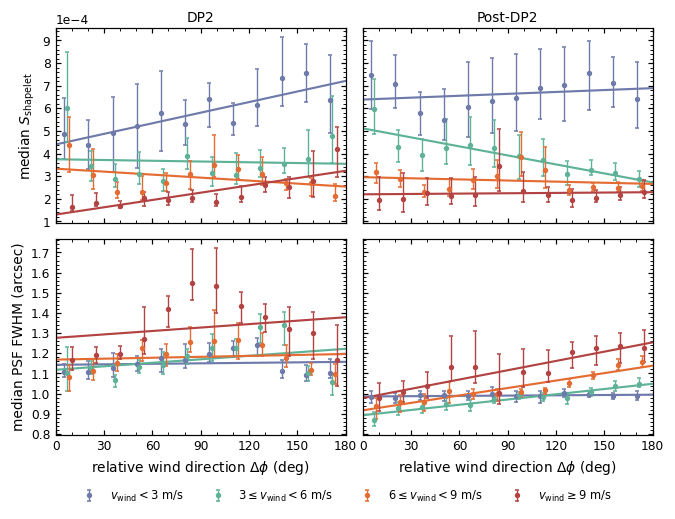

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(7.0, 4.8), sharex=True, sharey='row',
                         gridspec_kw=dict(hspace=0.08, wspace=0.06))
xfit = np.array([0.0, 180.0])
for j, epoch in enumerate(EPOCHS):
    for i, (col, ylab) in enumerate([('score', r'median $S_{\rm shapelet}$'),
                                     ('fwhm', 'median PSF FWHM (arcsec)')]):
        ax = axes[i, j]
        for k, (_, _, lab, c) in enumerate(WS_CLASSES):
            est, lo, hi = ctrl[(epoch, lab)][col]
            m, b, _ = ctrl[(epoch, lab)][f'{col}_fit'][0]
            ax.errorbar(MID + (k - 1.5) * 1.5, est, yerr=[est - lo, hi - est], fmt='o',
                        color=c, ms=2.5, lw=0.9, capsize=1.5, label=lab)
            ax.plot(xfit, m * xfit + b, color=c, lw=1.4)
        ax.set_xlim(0, 180)
        ax.xaxis.set_major_locator(MultipleLocator(30))
        ax.xaxis.set_minor_locator(MultipleLocator(10))
        if col == 'score':
            ax.yaxis.set_major_locator(MultipleLocator(1e-4))
            ax.yaxis.set_minor_locator(MultipleLocator(2e-5))
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
        else:
            ax.yaxis.set_major_locator(MultipleLocator(0.1))
            ax.yaxis.set_minor_locator(MultipleLocator(0.02))
        if j == 0:
            ax.set_ylabel(ylab)
        if i == 0:
            ax.set_xlabel(epoch)
            ax.xaxis.set_label_position('top')
        else:
            ax.set_xlabel(r'relative wind direction $\Delta\phi$ (deg)')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False,
           bbox_to_anchor=(0.5, -0.04), fontsize=7.5)
fig.savefig(FIG / 'score_vs_wind_direction_by_speed.pdf')
plt.show()

## Confounder checks

Relative wind angle is not assigned at random: it depends on azimuth, so it can carry
altitude (airmass), band mix and night-to-night seeing with it.
* **Altitude / wind speed per bin** — airmass alone broadens the PSF.
* **Band mix** — the score depends on band; re-do the into/behind contrast on the score
  divided by its per-band, per-epoch median.
* **DIMM seeing** — the free-atmosphere seeing from the DIMM (where available). If the FWHM
  trend is local (dome/tube) seeing, the DIMM should *not* show the same trend.

In [10]:
for epoch, df in data.items():
    g = df.assign(bin=pd.cut(df['dphi'], EDGES, include_lowest=True)).groupby('bin', observed=True)
    tab = pd.DataFrame({'N': g.size(),
                        'alt': g['altitude'].median(),
                        'v_wind': g['wind_speed'].median(),
                        'dimm': g['dimm_seeing'].median(),
                        'frac_i': g['band'].apply(lambda b: np.mean(b == 'i'))})
    print(f'\n{epoch}: per-bin medians (altitude deg, wind m/s, DIMM arcsec) and i-band fraction')
    print(tab.round(3).to_string())

print('\nbehind/into ratio  [16-84% night bootstrap]')
for epoch, df in data.items():
    df = df.copy()
    df['score_norm'] = df['score'] / df.groupby('band')['score'].transform('median')
    ok = df['dimm_seeing'].notna()
    tmp = df.rename(columns={'score': 'score_raw', 'score_norm': 'score'})
    e1, l1, h1 = night_bootstrap(tmp, into_vs_behind('score'))
    tmp = df[ok].rename(columns={'fwhm': 'fwhm_meas', 'dimm_seeing': 'fwhm'})
    e2, l2, h2 = night_bootstrap(tmp, into_vs_behind('fwhm'))
    e3, l3, h3 = night_bootstrap(df[ok], into_vs_behind('fwhm'))
    print(f'  {epoch:>9}: band-normalised score {e1[2]:.3f} [{l1[2]:.3f}, {h1[2]:.3f}]   '
          f'DIMM seeing {e2[2]:.3f} [{l2[2]:.3f}, {h2[2]:.3f}]   '
          f'measured FWHM (same DIMM visits) {e3[2]:.3f} [{l3[2]:.3f}, {h3[2]:.3f}]   '
          f'N_DIMM = {ok.sum():,}')


DP2: per-bin medians (altitude deg, wind m/s, DIMM arcsec) and i-band fraction
                   N     alt  v_wind   dimm  frac_i
bin                                                
(-0.001, 15.0]  1682  54.239   4.754  1.030   0.221
(15.0, 30.0]    1864  54.400   4.921  1.027   0.255
(30.0, 45.0]    2376  54.851   4.754  1.018   0.239
(45.0, 60.0]    2620  54.372   4.921  1.009   0.230
(60.0, 75.0]    2867  52.775   4.754  1.004   0.246
(75.0, 90.0]    2649  50.283   5.421  1.059   0.270
(90.0, 105.0]   2694  50.331   5.921  1.075   0.333
(105.0, 120.0]  2053  49.004   5.254  1.041   0.327
(120.0, 135.0]  1860  52.581   4.921  1.023   0.280
(135.0, 150.0]  1842  56.510   5.087  1.020   0.239
(150.0, 165.0]  1452  57.496   4.921  1.025   0.304
(165.0, 180.0]  1307  55.468   5.755  0.980   0.319

Post-DP2: per-bin medians (altitude deg, wind m/s, DIMM arcsec) and i-band fraction
                   N     alt  v_wind   dimm  frac_i
bin                                                
(-0

        DP2: band-normalised score 1.070 [0.906, 1.263]   DIMM seeing 0.986 [0.946, 1.024]   measured FWHM (same DIMM visits) 1.026 [0.980, 1.067]   N_DIMM = 18,229


   Post-DP2: band-normalised score 0.888 [0.791, 1.004]   DIMM seeing 1.000 [0.968, 1.034]   measured FWHM (same DIMM visits) 1.120 [1.089, 1.155]   N_DIMM = 33,721


In [11]:
# Per wind-speed bracket: is the FWHM trend local (dome/tube) seeing, or band mix / free atmosphere?
# Same straight-line fit as above, applied to the band-normalised FWHM and to the DIMM seeing.
print('fitted change from dphi = 0 to 180 deg   [16-84% night bootstrap]')
for epoch, df in data.items():
    df = df.copy()
    df['fwhm_norm'] = df['fwhm'] / df.groupby('band')['fwhm'].transform('median')
    for lo_v, hi_v, lab, _ in WS_CLASSES:
        sub = df[(df['wind_speed'] >= lo_v) & (df['wind_speed'] < hi_v)]
        a = night_bootstrap(sub.rename(columns={'fwhm': 'fwhm_raw', 'fwhm_norm': 'fwhm'}),
                            trend('fwhm'))
        d = sub[sub['dimm_seeing'].notna()]
        b = night_bootstrap(d.rename(columns={'fwhm': 'fwhm_raw', 'dimm_seeing': 'fwhm'}),
                            trend('fwhm'))
        print(f'  {epoch:>9} {lab:34s} band-norm. FWHM {a[0][2]:+6.1%} [{a[1][2]:+6.1%}, {a[2][2]:+6.1%}]'
              f'   DIMM {b[0][2]:+6.1%} [{b[1][2]:+6.1%}, {b[2][2]:+6.1%}]  (N_DIMM = {len(d):,})')

fitted change from dphi = 0 to 180 deg   [16-84% night bootstrap]


        DP2 $v_{\rm wind} < 3$ m/s             band-norm. FWHM  +2.6% [ -2.1%, +11.2%]   DIMM  -5.6% [-16.5%,  +4.5%]  (N_DIMM = 4,904)


        DP2 $3 \leq v_{\rm wind} < 6$ m/s      band-norm. FWHM +12.6% [ +1.9%, +20.4%]   DIMM  +1.0% [ -6.0%,  +6.8%]  (N_DIMM = 6,310)


        DP2 $6 \leq v_{\rm wind} < 9$ m/s      band-norm. FWHM  +4.7% [ -0.4%, +11.2%]   DIMM  -1.1% [ -7.8%,  +5.5%]  (N_DIMM = 4,021)


        DP2 $v_{\rm wind} \geq 9$ m/s          band-norm. FWHM +11.6% [ -0.7%, +24.5%]   DIMM +15.1% [ -2.0%, +43.3%]  (N_DIMM = 2,994)


   Post-DP2 $v_{\rm wind} < 3$ m/s             band-norm. FWHM  +0.7% [ -2.3%,  +3.3%]   DIMM  -5.5% [-11.0%,  +0.0%]  (N_DIMM = 8,637)


   Post-DP2 $3 \leq v_{\rm wind} < 6$ m/s      band-norm. FWHM +17.6% [+12.1%, +22.9%]   DIMM  +3.0% [ -1.0%,  +7.0%]  (N_DIMM = 12,554)


   Post-DP2 $6 \leq v_{\rm wind} < 9$ m/s      band-norm. FWHM +20.5% [+14.2%, +27.1%]   DIMM  -4.7% [ -9.7%,  -0.0%]  (N_DIMM = 8,752)


   Post-DP2 $v_{\rm wind} \geq 9$ m/s          band-norm. FWHM +22.8% [+10.0%, +31.5%]   DIMM +12.5% [ -7.5%, +29.7%]  (N_DIMM = 3,778)
